In [2]:
# Setup
import sys, subprocess, importlib.util, warnings, json, time, pickle, hashlib
from pathlib import Path
from datetime import datetime, timezone

warnings.filterwarnings("ignore")

required = ["pandas", "numpy", "matplotlib", "seaborn", "scikit-learn", "joblib"]
missing = [p for p in required if importlib.util.find_spec(p.replace("-", "_")) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q"] + missing)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
print("Python:", sys.version.split()[0])
print("Libraries ready.")

Python: 3.13.16
Libraries ready.


In [3]:
DATA_PATH = None

REQUIRED_COLUMNS = [
    "transaction_id", "amount", "transaction_hour", "merchant_category",
    "foreign_transaction", "location_mismatch", "device_trust_score",
    "velocity_last_24h", "cardholder_age", "is_fraud"
]
CANDIDATE_PATHS = [
    Path("/content/credit_card_fraud_10k.csv"),
    Path("/content/creditcard.csv"),
    Path("/content/fraud_transactions.csv"),
    Path("credit_card_fraud_10k.csv"),
    Path("fraud_transactions.csv"),
]
if DATA_PATH:
    candidate = Path(DATA_PATH)
    CANDIDATE_PATHS.insert(0, candidate)

csv_path = next((p for p in CANDIDATE_PATHS if p.exists()), None)
USING_SYNTHETIC_DATA = csv_path is None

if csv_path:
    data = pd.read_csv(csv_path, low_memory=False)
    print("Loaded CSV:", csv_path)
else:
    print("No compatible CSV found. Creating SYNTHETIC DEMO DATA (not real transaction data).")
    rng = np.random.default_rng(RANDOM_STATE)
    n = 20000
    categories = np.array(["Electronics", "Travel", "Grocery", "Food", "Clothing", "Fuel", "Digital"])
    amount = np.round(np.clip(rng.gamma(2.0, 90, n), 1, 2500), 2)
    hour = rng.integers(0, 24, n)
    foreign = rng.binomial(1, 0.12, n)
    mismatch = rng.binomial(1, 0.10, n)
    device = rng.integers(15, 101, n)
    velocity = np.clip(rng.poisson(2.0, n), 0, 20)
    age = rng.integers(18, 86, n)
    category = rng.choice(categories, n, p=[.16, .12, .22, .18, .12, .10, .10])
    # A synthetic risk-generating process for a demonstrator, not a real fraud rule.
    logit = (
        -5.0 + 1.25*foreign + 1.35*mismatch + .16*velocity
        + .85*(device < 40) + .65*((hour <= 4) | (hour >= 23))
        + .00045*amount + .35*np.isin(category, ["Electronics", "Digital", "Travel"])
    )
    probability = 1 / (1 + np.exp(-logit))
    label = rng.binomial(1, probability)
    data = pd.DataFrame({
        "transaction_id": [f"TXN{i:07d}" for i in range(1, n+1)],
        "amount": amount, "transaction_hour": hour, "merchant_category": category,
        "foreign_transaction": foreign, "location_mismatch": mismatch,
        "device_trust_score": device, "velocity_last_24h": velocity,
        "cardholder_age": age, "is_fraud": label
    })

# Normalize column names and validate schema
data.columns = [str(c).strip() for c in data.columns]
missing_cols = sorted(set(REQUIRED_COLUMNS) - set(data.columns))
if missing_cols:
    raise ValueError(
        f"Dataset is missing required columns: {missing_cols}. "
        "Map your CSV's fields to the documented schema in the previous cell."
    )

data = data[REQUIRED_COLUMNS].copy()
data["is_fraud"] = pd.to_numeric(data["is_fraud"], errors="coerce")
data = data.dropna(subset=["is_fraud"])
data["is_fraud"] = data["is_fraud"].astype(int)
if not set(data["is_fraud"].unique()).issubset({0, 1}):
    raise ValueError("is_fraud must contain only 0 and 1.")
if data["is_fraud"].nunique() < 2:
    raise ValueError("Both classes (0 and 1) must be present to train/evaluate a classifier.")

data["amount"] = pd.to_numeric(data["amount"], errors="coerce")
numeric_cols = ["amount", "transaction_hour", "foreign_transaction", "location_mismatch",
                "device_trust_score", "velocity_last_24h", "cardholder_age"]
for col in numeric_cols:
    data[col] = pd.to_numeric(data[col], errors="coerce")
data["merchant_category"] = data["merchant_category"].fillna("Unknown").astype(str)
data = data.dropna(subset=["amount"])
data = data.drop_duplicates(subset=["transaction_id"], keep="first").reset_index(drop=True)

print(f"Rows: {len(data):,} | Features: {len(REQUIRED_COLUMNS)-2} | Synthetic demo: {USING_SYNTHETIC_DATA}")
display(data.head())

Loaded CSV: /content/credit_card_fraud_10k.csv
Rows: 10,000 | Features: 8 | Synthetic demo: False


,transaction_id,amount,transaction_hour,merchant_category,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
0,1,84.47,22,Electronics,0,0,66,3,40,0
1,2,541.82,3,Travel,1,0,87,1,64,0
2,3,237.01,17,Grocery,0,0,49,1,61,0
3,4,164.33,4,Grocery,0,1,72,3,34,0
4,5,30.53,15,Food,0,0,79,0,44,0


In [4]:
quality = pd.DataFrame({
    "dtype": data.dtypes.astype(str),
    "missing_count": data.isna().sum(),
    "missing_pct": (100 * data.isna().mean()).round(2),
    "unique_values": data.nunique()
})
display(quality)
print("Duplicate transaction IDs:", int(data["transaction_id"].duplicated().sum()))
print("Target counts:")
display(data["is_fraud"].value_counts().rename(index={0:"Legitimate", 1:"Fraud"}).to_frame("transactions"))
print(f"Fraud rate: {data['is_fraud'].mean():.3%}")

,dtype,missing_count,missing_pct,unique_values
transaction_id,int64,0,0.0,10000
amount,float64,0,0.0,8788
transaction_hour,int64,0,0.0,24
merchant_category,object,0,0.0,5
foreign_transaction,int64,0,0.0,2
location_mismatch,int64,0,0.0,2
device_trust_score,int64,0,0.0,75
velocity_last_24h,int64,0,0.0,10
cardholder_age,int64,0,0.0,52
is_fraud,int64,0,0.0,2


Duplicate transaction IDs: 0
Target counts:


,transactions
is_fraud,
Legitimate,9849
Fraud,151


Fraud rate: 1.510%


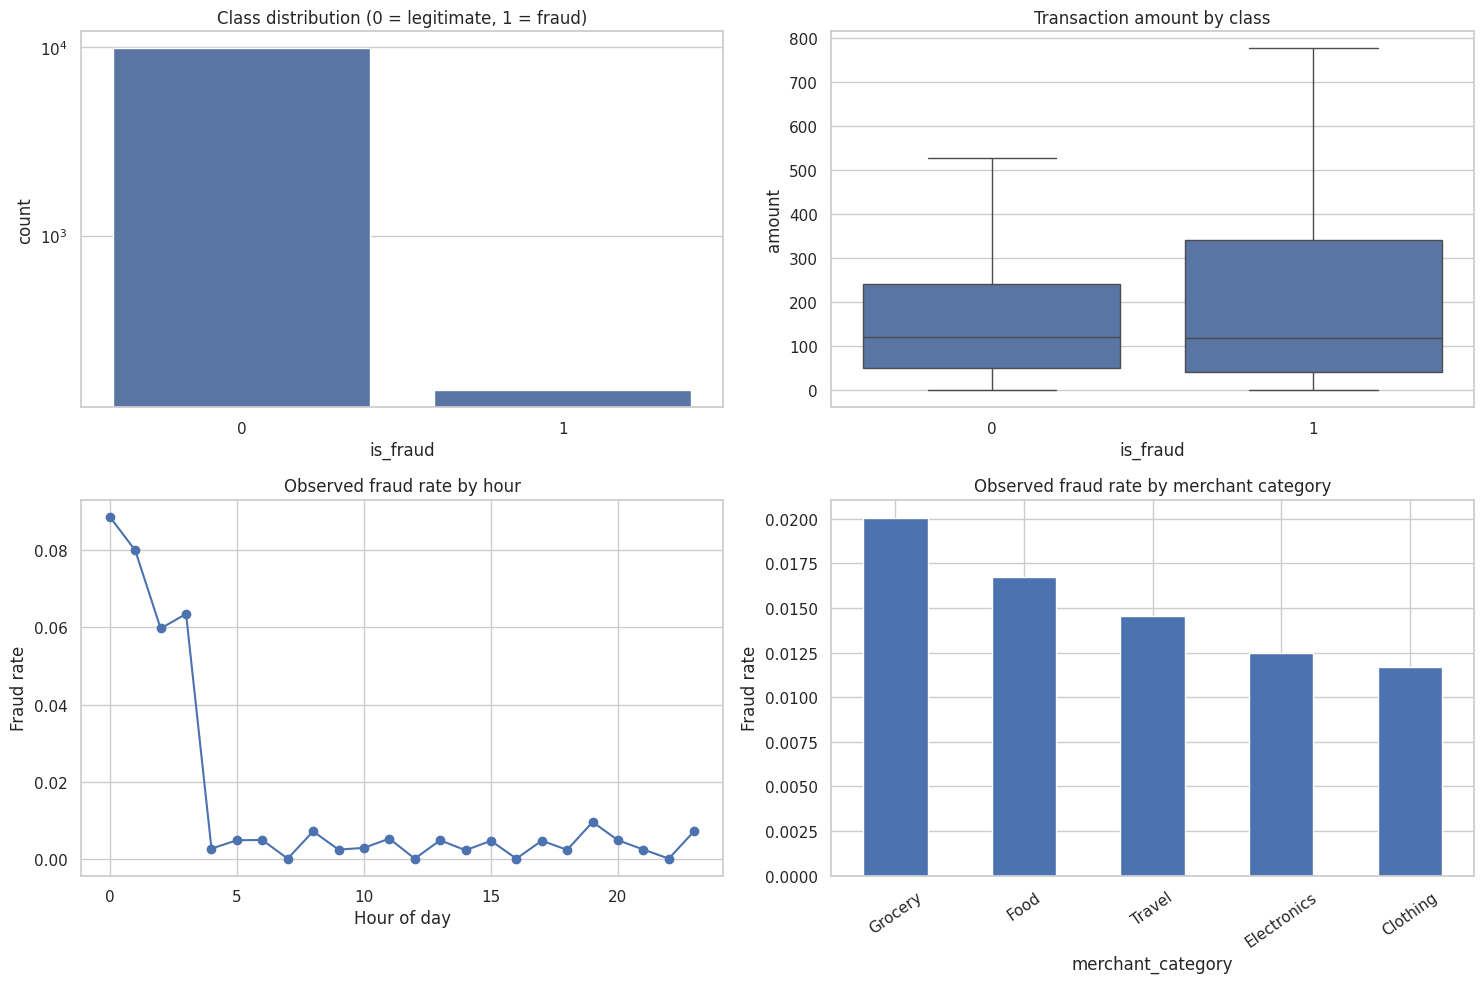

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
sns.countplot(data=data, x="is_fraud", ax=axes[0,0])
axes[0,0].set_title("Class distribution (0 = legitimate, 1 = fraud)")
axes[0,0].set_yscale("log")

sns.boxplot(data=data, x="is_fraud", y="amount", showfliers=False, ax=axes[0,1])
axes[0,1].set_title("Transaction amount by class")

fraud_by_hour = data.groupby("transaction_hour")["is_fraud"].mean()
axes[1,0].plot(fraud_by_hour.index, fraud_by_hour.values, marker="o")
axes[1,0].set_title("Observed fraud rate by hour")
axes[1,0].set_xlabel("Hour of day")
axes[1,0].set_ylabel("Fraud rate")

category_rate = data.groupby("merchant_category")["is_fraud"].mean().sort_values(ascending=False)
category_rate.plot(kind="bar", ax=axes[1,1])
axes[1,1].set_title("Observed fraud rate by merchant category")
axes[1,1].set_ylabel("Fraud rate")
axes[1,1].tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

In [6]:
X = data.drop(columns=["is_fraud", "transaction_id"])
y = data["is_fraud"].astype(int)

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, test_size=0.25, stratify=y_train_full,
    random_state=RANDOM_STATE
)

numeric_features = [
    "amount", "transaction_hour", "foreign_transaction", "location_mismatch",
    "device_trust_score", "velocity_last_24h", "cardholder_age"
]
categorical_features = ["merchant_category"]

def make_preprocessor():
    return ColumnTransformer(transformers=[
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numeric_features),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_features)
    ])

print(f"Train: {len(X_train):,} | Validation: {len(X_valid):,} | Test: {len(X_test):,}")
print(f"Fraud rates — train {y_train.mean():.3%}, validation {y_valid.mean():.3%}, test {y_test.mean():.3%}")

Train: 6,000 | Validation: 2,000 | Test: 2,000
Fraud rates — train 1.517%, validation 1.500%, test 1.500%


,model,PR-AUC,ROC-AUC,precision@0.50,recall@0.50,F1@0.50,fit_seconds
0,Random Forest,0.998925,0.999983,1.000000,0.833333,0.909091,1.789395
1,Logistic Regression,0.646360,0.992386,0.272727,1.000000,0.428571,0.185700


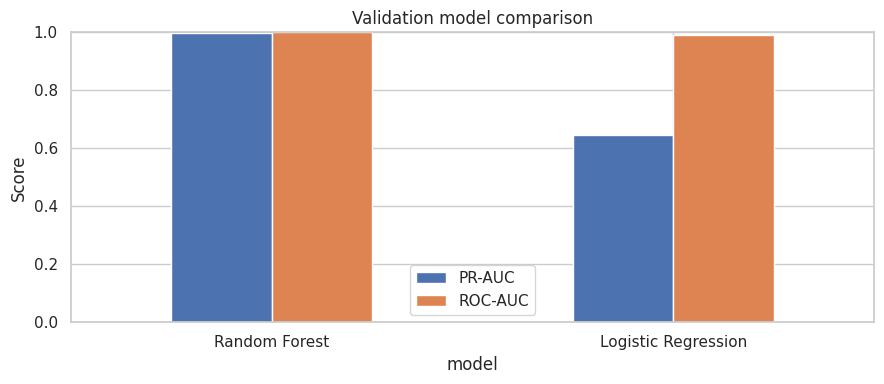

Selected model by validation PR-AUC: Random Forest


In [7]:
models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE))
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", RandomForestClassifier(
            n_estimators=250, min_samples_leaf=3,
            class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1
        ))
    ])
}

validation_rows = []
validation_probabilities = {}
for name, pipeline in models.items():
    started = time.perf_counter()
    pipeline.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - started
    probs = pipeline.predict_proba(X_valid)[:, 1]
    validation_probabilities[name] = probs
    preds_05 = (probs >= 0.5).astype(int)
    validation_rows.append({
        "model": name,
        "PR-AUC": average_precision_score(y_valid, probs),
        "ROC-AUC": roc_auc_score(y_valid, probs),
        "precision@0.50": precision_score(y_valid, preds_05, zero_division=0),
        "recall@0.50": recall_score(y_valid, preds_05, zero_division=0),
        "F1@0.50": f1_score(y_valid, preds_05, zero_division=0),
        "fit_seconds": fit_seconds
    })

validation_summary = pd.DataFrame(validation_rows).sort_values("PR-AUC", ascending=False).reset_index(drop=True)
display(validation_summary)
ax = validation_summary.set_index("model")[["PR-AUC", "ROC-AUC"]].plot(kind="bar", figsize=(9,4), ylim=(0,1))
ax.set_title("Validation model comparison")
ax.set_ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

best_model_name = validation_summary.iloc[0]["model"]
best_model = models[best_model_name]
valid_prob = validation_probabilities[best_model_name]
print("Selected model by validation PR-AUC:", best_model_name)

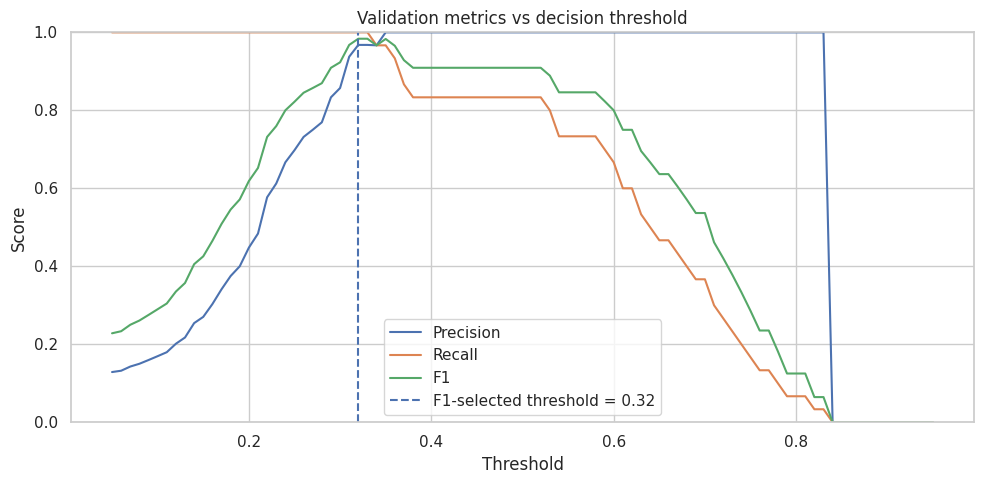

Validation-selected threshold: 0.32


,threshold,precision,recall,f1,alerts_per_1000
27,0.32,0.967742,1.0,0.983607,15.5


In [8]:
threshold_rows = []
for threshold in np.arange(0.05, 0.96, 0.01):
    pred = (valid_prob >= threshold).astype(int)
    threshold_rows.append({
        "threshold": threshold,
        "precision": precision_score(y_valid, pred, zero_division=0),
        "recall": recall_score(y_valid, pred, zero_division=0),
        "f1": f1_score(y_valid, pred, zero_division=0),
        "alerts_per_1000": pred.mean() * 1000
    })
threshold_table = pd.DataFrame(threshold_rows)
best_threshold = float(threshold_table.loc[threshold_table["f1"].idxmax(), "threshold"])

fig, ax = plt.subplots(figsize=(10,5))
for metric in ["precision", "recall", "f1"]:
    ax.plot(threshold_table["threshold"], threshold_table[metric], label=metric.title())
ax.axvline(best_threshold, linestyle="--", label=f"F1-selected threshold = {best_threshold:.2f}")
ax.set(title="Validation metrics vs decision threshold", xlabel="Threshold", ylabel="Score", ylim=(0,1))
ax.legend()
plt.tight_layout()
plt.show()

print(f"Validation-selected threshold: {best_threshold:.2f}")
display(threshold_table.iloc[(threshold_table["threshold"]-best_threshold).abs().argsort()[:1]])

,test_score
Accuracy,0.9985
Precision,0.9355
Recall,0.9667
F1,0.9508
ROC-AUC,0.9997
PR-AUC / Average Precision,0.9864
False positive rate,0.0010


              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00      1970
       Fraud       0.94      0.97      0.95        30

    accuracy                           1.00      2000
   macro avg       0.97      0.98      0.98      2000
weighted avg       1.00      1.00      1.00      2000



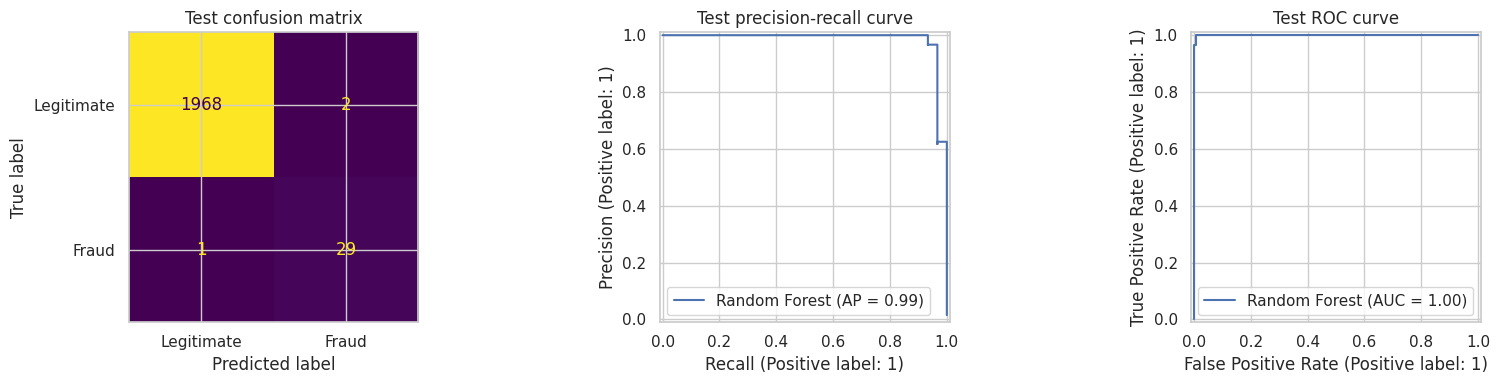

In [9]:
test_prob = best_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= best_threshold).astype(int)

final_metrics = {
    "Accuracy": accuracy_score(y_test, test_pred),
    "Precision": precision_score(y_test, test_pred, zero_division=0),
    "Recall": recall_score(y_test, test_pred, zero_division=0),
    "F1": f1_score(y_test, test_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_prob),
    "PR-AUC / Average Precision": average_precision_score(y_test, test_prob),
    "False positive rate": ((test_pred == 1) & (y_test.to_numpy() == 0)).sum() / max((y_test.to_numpy() == 0).sum(), 1)
}
final_metrics_df = pd.DataFrame.from_dict(final_metrics, orient="index", columns=["test_score"])
display(final_metrics_df.style.format("{:.4f}"))
print(classification_report(y_test, test_pred, target_names=["Legitimate", "Fraud"], zero_division=0))

fig, axes = plt.subplots(1, 3, figsize=(17,4))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=["Legitimate","Fraud"], colorbar=False, ax=axes[0])
axes[0].set_title("Test confusion matrix")
PrecisionRecallDisplay.from_predictions(y_test, test_prob, ax=axes[1], name=best_model_name)
axes[1].set_title("Test precision-recall curve")
RocCurveDisplay.from_predictions(y_test, test_prob, ax=axes[2], name=best_model_name)
axes[2].set_title("Test ROC curve")
plt.tight_layout()
plt.show()

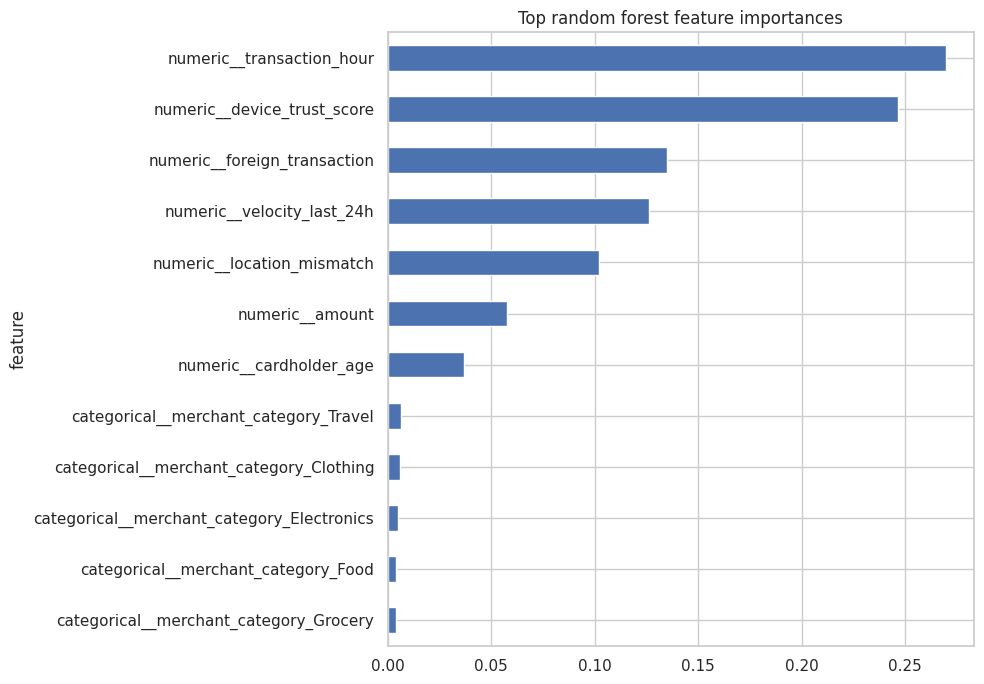

In [10]:
fitted_preprocessor = best_model.named_steps["preprocessor"]
fitted_estimator = best_model.named_steps["model"]
try:
    feature_names = fitted_preprocessor.get_feature_names_out()
    if hasattr(fitted_estimator, "coef_"):
        values = fitted_estimator.coef_[0]
        importance = pd.DataFrame({"feature": feature_names, "value": values})
        importance["abs_value"] = importance["value"].abs()
        importance = importance.sort_values("abs_value", ascending=False).head(20)
        ax = importance.sort_values("value").plot(
            x="feature", y="value", kind="barh", figsize=(10,7), legend=False
        )
        ax.set_title("Top logistic regression coefficients")
        ax.set_xlabel("Coefficient (direction and magnitude)")
        plt.tight_layout()
        plt.show()
    elif hasattr(fitted_estimator, "feature_importances_"):
        importance = pd.DataFrame({
            "feature": feature_names,
            "importance": fitted_estimator.feature_importances_
        }).sort_values("importance", ascending=False).head(20)
        ax = importance.sort_values("importance").plot(
            x="feature", y="importance", kind="barh", figsize=(10,7), legend=False
        )
        ax.set_title("Top random forest feature importances")
        plt.tight_layout()
        plt.show()
except Exception as exc:
    print("Feature-level interpretation unavailable:", exc)

In [11]:
best_model.fit(X_train_full, y_train_full)
MODEL_VERSION = "fraud-risk-model-v1"
model_artifact = {
    "pipeline": best_model,
    "threshold": best_threshold,
    "model_name": best_model_name,
    "feature_columns": list(X.columns),
    "target_column": "is_fraud",
    "model_version": MODEL_VERSION,
    "random_state": RANDOM_STATE,
    "synthetic_demo_data": USING_SYNTHETIC_DATA,
    "validation_selection_metric": "PR-AUC",
    "threshold_selection_metric": "F1 on validation"
}
artifact_path = Path("/content/fraud_detection_model.joblib") if Path("/content").exists() else Path("fraud_detection_model.joblib")
joblib.dump(model_artifact, artifact_path)
print("Saved:", artifact_path)
print("Model version:", MODEL_VERSION)

Saved: /content/fraud_detection_model.joblib
Model version: fraud-risk-model-v1


In [12]:
def score_transaction(transaction: dict, artifact=model_artifact):
    required_features = artifact["feature_columns"]
    row = pd.DataFrame([transaction])
    missing = sorted(set(required_features) - set(row.columns))
    if missing:
        raise ValueError(f"Missing features: {missing}")
    row = row[required_features]
    prob = float(artifact["pipeline"].predict_proba(row)[:, 1][0])
    threshold = float(artifact["threshold"])
    # Demo triage bands; configurable separately from the model threshold.
    if prob >= max(threshold, 0.70):
        risk, action = "HIGH", "ESCALATE_FOR_REVIEW"
    elif prob >= threshold:
        risk, action = "MEDIUM", "MANUAL_REVIEW"
    else:
        risk, action = "LOW", "STANDARD_PROCESSING"
    return {
        "fraud_probability": prob,
        "model_threshold": threshold,
        "risk_level": risk,
        "recommended_action": action,
        "model_version": artifact["model_version"]
    }

# EDIT THESE VALUES to test a different transaction.
sample_transaction = {
    "amount": 920.50,
    "transaction_hour": 2,
    "merchant_category": "Travel",
    "foreign_transaction": 1,
    "location_mismatch": 1,
    "device_trust_score": 28,
    "velocity_last_24h": 9,
    "cardholder_age": 36
}
single_result = score_transaction(sample_transaction)
display(pd.DataFrame([single_result]).style.format({"fraud_probability": "{:.2%}", "model_threshold": "{:.2f}"}))

,fraud_probability,model_threshold,risk_level,recommended_action,model_version
0,87.60%,0.32,HIGH,ESCALATE_FOR_REVIEW,fraud-risk-model-v1


In [13]:
FRESHNESS_SLA_SECONDS = 30
REPLAY_EVENTS = min(5000, len(X_test))
BATCH_SIZE = 250
SIMULATED_EVENT_SPACING_SECONDS = 0.05

replay_X = X_test.iloc[:REPLAY_EVENTS].copy().reset_index(drop=True)
replay_y = y_test.iloc[:REPLAY_EVENTS].reset_index(drop=True)
replay_ids = data.loc[X_test.index[:REPLAY_EVENTS], "transaction_id"].reset_index(drop=True) if all(i in data.index for i in X_test.index[:REPLAY_EVENTS]) else pd.Series([f"REPLAY{i:07d}" for i in range(REPLAY_EVENTS)])

event_rows = []
stream_start = time.perf_counter()
base_event_time = pd.Timestamp.now(tz="UTC")

for start in range(0, REPLAY_EVENTS, BATCH_SIZE):
    end = min(start + BATCH_SIZE, REPLAY_EVENTS)
    batch_X = replay_X.iloc[start:end]
    batch_probs = best_model.predict_proba(batch_X)[:, 1]
    batch_done_wall = pd.Timestamp.now(tz="UTC")
    batch_processing_ms = (time.perf_counter() - stream_start) * 1000
    for j, prob in enumerate(batch_probs, start=start):
        event_time = base_event_time + pd.to_timedelta(j * SIMULATED_EVENT_SPACING_SECONDS, unit="s")
        ingestion_time = pd.Timestamp.now(tz="UTC")
        processing_time = pd.Timestamp.now(tz="UTC")
        latency_ms = max(0.0, (processing_time - ingestion_time).total_seconds() * 1000)
        freshness_seconds = max(0.0, (processing_time - event_time).total_seconds())
        if prob >= max(best_threshold, 0.70):
            risk_level, action = "HIGH", "ESCALATE_FOR_REVIEW"
        elif prob >= best_threshold:
            risk_level, action = "MEDIUM", "MANUAL_REVIEW"
        else:
            risk_level, action = "LOW", "STANDARD_PROCESSING"
        event_rows.append({
            "transaction_id": str(replay_ids.iloc[j]),
            "event_time_utc": event_time.isoformat(),
            "ingestion_time_utc": ingestion_time.isoformat(),
            "processing_time_utc": processing_time.isoformat(),
            "processing_latency_ms": latency_ms,
            "freshness_latency_seconds": freshness_seconds,
            "freshness_sla_met": freshness_seconds <= FRESHNESS_SLA_SECONDS,
            "amount": float(replay_X.iloc[j]["amount"]),
            "merchant_category": str(replay_X.iloc[j]["merchant_category"]),
            "fraud_probability": float(prob),
            "predicted_fraud": int(prob >= best_threshold),
            "risk_level": risk_level,
            "recommended_action": action,
            "model_version": MODEL_VERSION,
            "label_available_for_evaluation": True,
            "actual_is_fraud": int(replay_y.iloc[j])
        })

events = pd.DataFrame(event_rows)
total_wall_seconds = max(time.perf_counter() - stream_start, 1e-9)
throughput = len(events) / total_wall_seconds
events.head()

,transaction_id,event_time_utc,ingestion_time_utc,processing_time_utc,processing_latency_ms,freshness_latency_seconds,freshness_sla_met,amount,merchant_category,fraud_probability,predicted_fraud,risk_level,recommended_action,model_version,label_available_for_evaluation,actual_is_fraud
0,9945,2026-10-08T17:56:20.160270+00:00,2026-10-08T17:56:20.238018+00:00,2026-10-08T17:56:20.238032+00:00,0.014,0.077762,True,61.48,Clothing,0.000000,0,LOW,STANDARD_PROCESSING,fraud-risk-model-v1,True,0
1,2602,2026-10-08T17:56:20.210270+00:00,2026-10-08T17:56:20.238898+00:00,2026-10-08T17:56:20.238910+00:00,0.012,0.028640,True,10.06,Grocery,0.018657,0,LOW,STANDARD_PROCESSING,fraud-risk-model-v1,True,0
2,343,2026-10-08T17:56:20.260270+00:00,2026-10-08T17:56:20.239560+00:00,2026-10-08T17:56:20.239570+00:00,0.010,0.000000,True,34.24,Electronics,0.000000,0,LOW,STANDARD_PROCESSING,fraud-risk-model-v1,True,0
3,3223,2026-10-08T17:56:20.310270+00:00,2026-10-08T17:56:20.240042+00:00,2026-10-08T17:56:20.240053+00:00,0.011,0.000000,True,15.71,Travel,0.003906,0,LOW,STANDARD_PROCESSING,fraud-risk-model-v1,True,0
4,5217,2026-10-08T17:56:20.360270+00:00,2026-10-08T17:56:20.240581+00:00,2026-10-08T17:56:20.240592+00:00,0.011,0.000000,True,105.84,Clothing,0.000000,0,LOW,STANDARD_PROCESSING,fraud-risk-model-v1,True,0


,value
transactions_processed,2000.000000
predicted_high_risk,10.000000
predicted_medium_risk,19.000000
predicted_fraud_count,29.000000
actual_fraud_count_in_replay,30.000000
observed_fraud_rate_in_replay,0.015000
mean_fraud_probability,0.024940
throughput_events_per_second,892.896566
mean_processing_latency_ms,0.016854
p95_processing_latency_ms,0.013000


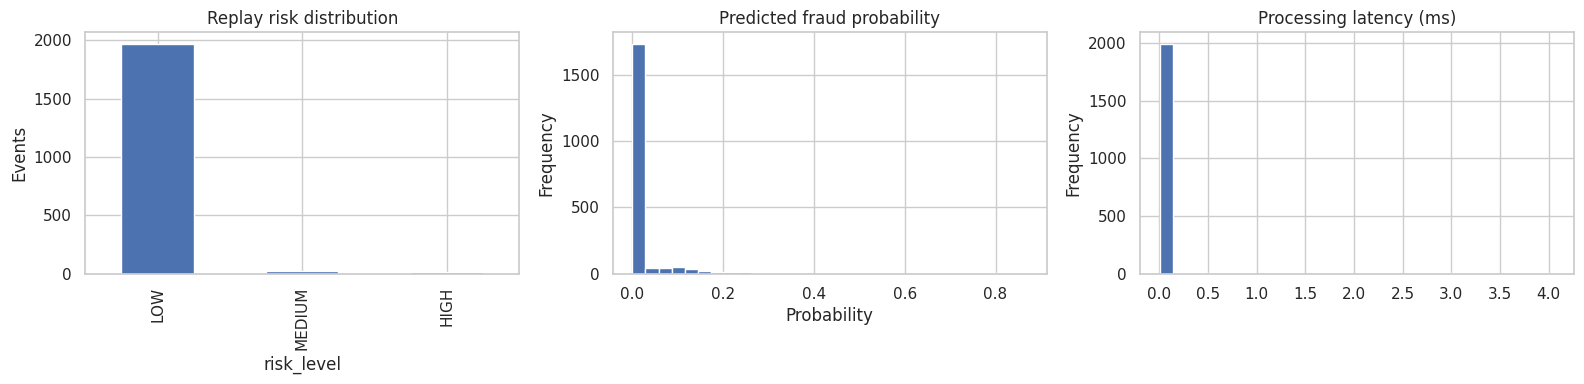

In [14]:
def percentile(series, q):
    return float(np.percentile(series, q)) if len(series) else float("nan")

ops_kpis = pd.DataFrame([{
    "transactions_processed": len(events),
    "predicted_high_risk": int((events["risk_level"] == "HIGH").sum()),
    "predicted_medium_risk": int((events["risk_level"] == "MEDIUM").sum()),
    "predicted_fraud_count": int(events["predicted_fraud"].sum()),
    "actual_fraud_count_in_replay": int(events["actual_is_fraud"].sum()),
    "observed_fraud_rate_in_replay": float(events["actual_is_fraud"].mean()),
    "mean_fraud_probability": float(events["fraud_probability"].mean()),
    "throughput_events_per_second": throughput,
    "mean_processing_latency_ms": float(events["processing_latency_ms"].mean()),
    "p95_processing_latency_ms": percentile(events["processing_latency_ms"], 95),
    "freshness_sla_seconds": FRESHNESS_SLA_SECONDS,
    "freshness_sla_compliance_pct": float(100 * events["freshness_sla_met"].mean())
}])
display(ops_kpis.T.rename(columns={0:"value"}))

fig, axes = plt.subplots(1, 3, figsize=(16,4))
events["risk_level"].value_counts().reindex(["LOW","MEDIUM","HIGH"], fill_value=0).plot(kind="bar", ax=axes[0])
axes[0].set_title("Replay risk distribution")
axes[0].set_ylabel("Events")
events["fraud_probability"].plot(kind="hist", bins=30, ax=axes[1])
axes[1].set_title("Predicted fraud probability")
axes[1].set_xlabel("Probability")
events["processing_latency_ms"].plot(kind="hist", bins=30, ax=axes[2])
axes[2].set_title("Processing latency (ms)")
plt.tight_layout()
plt.show()

In [15]:
HIGH_RISK_RATE_ALERT_PCT = 5.0
MIN_EVENTS_FOR_RATE_ALERT = 100
P95_LATENCY_ALERT_MS = 250.0
MIN_FRESHNESS_SLA_COMPLIANCE_PCT = 99.0

high_risk_rate_pct = 100 * events["predicted_fraud"].mean()
p95_latency = percentile(events["processing_latency_ms"], 95)
sla_compliance_pct = 100 * events["freshness_sla_met"].mean()

alerts = []
if len(events) >= MIN_EVENTS_FOR_RATE_ALERT and high_risk_rate_pct > HIGH_RISK_RATE_ALERT_PCT:
    alerts.append({"severity":"WARNING","alert":"Predicted fraud rate above threshold",
                   "observed":f"{high_risk_rate_pct:.2f}%", "threshold":f"{HIGH_RISK_RATE_ALERT_PCT:.2f}%"})
if p95_latency > P95_LATENCY_ALERT_MS:
    alerts.append({"severity":"WARNING","alert":"p95 processing latency exceeded",
                   "observed":f"{p95_latency:.2f} ms", "threshold":f"{P95_LATENCY_ALERT_MS:.2f} ms"})
if sla_compliance_pct < MIN_FRESHNESS_SLA_COMPLIANCE_PCT:
    alerts.append({"severity":"CRITICAL","alert":"Freshness SLA compliance below target",
                   "observed":f"{sla_compliance_pct:.2f}%", "threshold":f"{MIN_FRESHNESS_SLA_COMPLIANCE_PCT:.2f}%"})

if alerts:
    alerts_df = pd.DataFrame(alerts)
    print("ALERTS TRIGGERED")
    display(alerts_df)
else:
    alerts_df = pd.DataFrame(columns=["severity","alert","observed","threshold"])
    print("No operational thresholds breached in this replay.")

No operational thresholds breached in this replay.


,batch_size,elapsed_ms,avg_ms_per_transaction,transactions_per_second
0,1,141.701513,141.701513,7.057088
1,10,78.452369,7.845237,127.465877
2,100,76.005879,0.760059,1315.687698
3,1000,135.007954,0.135008,7406.971000


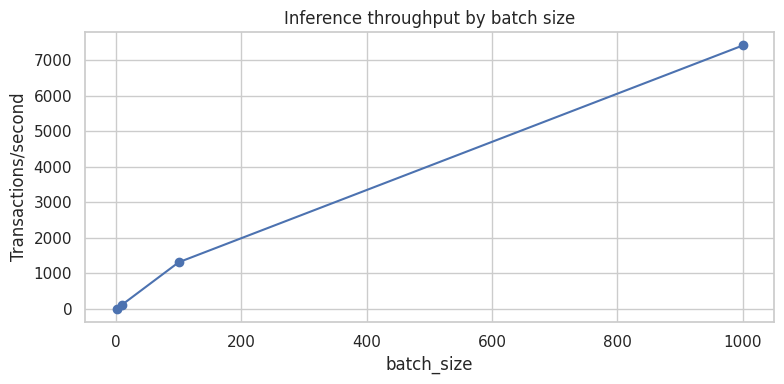

Note: true concurrent-load testing should be performed against a deployed API using a load-testing tool.


In [16]:
benchmark_rows = []
for n_rows in sorted(set([min(1, len(X_test)), min(10, len(X_test)), min(100, len(X_test)), min(1000, len(X_test))])):
    sample = X_test.iloc[:n_rows]
    t0 = time.perf_counter()
    _ = best_model.predict_proba(sample)
    elapsed = time.perf_counter() - t0
    benchmark_rows.append({
        "batch_size": n_rows,
        "elapsed_ms": elapsed * 1000,
        "avg_ms_per_transaction": elapsed * 1000 / n_rows,
        "transactions_per_second": n_rows / max(elapsed, 1e-9)
    })
benchmark_df = pd.DataFrame(benchmark_rows)
display(benchmark_df)
ax = benchmark_df.plot(x="batch_size", y="transactions_per_second", marker="o", figsize=(8,4), legend=False)
ax.set_title("Inference throughput by batch size")
ax.set_ylabel("Transactions/second")
plt.tight_layout()
plt.show()
print("Note: true concurrent-load testing should be performed against a deployed API using a load-testing tool.")

In [17]:
OUTPUT_DIR = Path("/content/fraud_project_outputs") if Path("/content").exists() else Path("fraud_project_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

events_path = OUTPUT_DIR / "scored_transaction_events.csv"
kpis_path = OUTPUT_DIR / "operational_kpis.csv"
metrics_path = OUTPUT_DIR / "model_test_metrics.csv"
alerts_path = OUTPUT_DIR / "operational_alerts.csv"
threshold_path = OUTPUT_DIR / "validation_threshold_curve.csv"
benchmark_path = OUTPUT_DIR / "inference_benchmark.csv"

events.to_csv(events_path, index=False)
ops_kpis.to_csv(kpis_path, index=False)
final_metrics_df.to_csv(metrics_path)
alerts_df.to_csv(alerts_path, index=False)
threshold_table.to_csv(threshold_path, index=False)
benchmark_df.to_csv(benchmark_path, index=False)

print("Exported files:")
for p in [events_path, kpis_path, metrics_path, alerts_path, threshold_path, benchmark_path, artifact_path]:
    print(" -", p)

Exported files:
 - /content/fraud_project_outputs/scored_transaction_events.csv
 - /content/fraud_project_outputs/operational_kpis.csv
 - /content/fraud_project_outputs/model_test_metrics.csv
 - /content/fraud_project_outputs/operational_alerts.csv
 - /content/fraud_project_outputs/validation_threshold_curve.csv
 - /content/fraud_project_outputs/inference_benchmark.csv
 - /content/fraud_detection_model.joblib


In [18]:
try:
    import ipywidgets as widgets
    from IPython.display import display, clear_output

    amount_w = widgets.FloatSlider(value=250, min=1, max=2500, step=25, description="Amount")
    hour_w = widgets.IntSlider(value=14, min=0, max=23, description="Hour")
    category_w = widgets.Dropdown(options=sorted(data["merchant_category"].astype(str).unique()),
                                  value=str(data["merchant_category"].mode().iloc[0]),
                                  description="Category")
    foreign_w = widgets.Dropdown(options=[("No",0),("Yes",1)], value=0, description="Foreign")
    mismatch_w = widgets.Dropdown(options=[("No",0),("Yes",1)], value=0, description="Location mismatch")
    device_w = widgets.IntSlider(value=75, min=0, max=100, description="Device trust")
    velocity_w = widgets.IntSlider(value=2, min=0, max=20, description="Velocity")
    age_w = widgets.IntSlider(value=35, min=18, max=100, description="Age")
    score_button = widgets.Button(description="Score transaction", button_style="primary")
    score_output = widgets.Output()

    def on_score_clicked(_):
        with score_output:
            clear_output()
            transaction = {
                "amount": amount_w.value,
                "transaction_hour": hour_w.value,
                "merchant_category": category_w.value,
                "foreign_transaction": foreign_w.value,
                "location_mismatch": mismatch_w.value,
                "device_trust_score": device_w.value,
                "velocity_last_24h": velocity_w.value,
                "cardholder_age": age_w.value
            }
            display(pd.DataFrame([score_transaction(transaction)]).style.format({
                "fraud_probability":"{:.2%}", "model_threshold":"{:.2f}"
            }))
    score_button.on_click(on_score_clicked)
    display(widgets.VBox([
        amount_w, hour_w, category_w, foreign_w, mismatch_w,
        device_w, velocity_w, age_w, score_button, score_output
    ]))
except Exception as e:
    print("ipywidgets controls unavailable in this runtime. Use Section 10's editable sample_transaction dictionary.")
    print("Reason:", str(e))